# Meta-Analysis of Research Papers on Large Language Models
## Theme: *Making LLMs efficient, from pre-training to fine-tuning*

**Mini project 1 (Week 17, Day 1).** A critical meta-analysis of five influential papers on the efficiency of large language models. Every paper answers the same question at a different stage of the LLM life-cycle: *how do we get the most capability per unit of compute and memory?*

The report is written in Markdown. A few small code cells **reproduce key quantitative claims** of the papers: the Chinchilla tokens-per-parameter rule, the LoRA parameter savings, and QLoRA memory budgets. They also draw the comparison charts. Everything runs on CPU in a few seconds.

In [1]:
!pip install -q "transformers<5" peft matplotlib pandas

In [2]:
import os
os.environ["USE_TF"] = "0"
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import display, Markdown
pd.set_option("display.max_colwidth", 140); pd.set_option("display.width", 200)

## 1. Introduction

**Large Language Models (LLMs)** are Transformer networks with billions of parameters, pre-trained with a next-token objective on hundreds of billions to trillions of tokens, then adapted (instruction tuning, RLHF, task fine-tuning) to follow instructions. Their capability improves predictably with scale, but so does their cost: training GPT-3 (175 B parameters) took thousands of GPU-days, and simply *fine-tuning* such a model with full precision needs hundreds of gigabytes of GPU memory. Efficiency has therefore become a central research topic. It decides *who* can build, adapt and deploy LLMs.

**Goal of this meta-analysis.** Rather than summarising papers one by one, we compare **five papers that attack the efficiency problem at different points of the pipeline**:
1. *how big* a model should be for a given compute budget;
2. *how* to train a strong model efficiently with public data;
3. *how* to compute attention efficiently;
4. *how* to fine-tune efficiently;
5. *how* to fine-tune even large models on a single GPU.

We extract common methods, trade-offs, limitations and future directions.

**Connecting theme:** compute- and memory-efficient LLMs (scaling laws → efficient architectures and kernels → parameter-efficient fine-tuning → quantization).

| # | Title | Publication source |
|---|---|---|
| P1 | *Training Compute-Optimal Large Language Models* (Chinchilla) | NeurIPS 2022 (arXiv:2203.15556) |
| P2 | *LLaMA: Open and Efficient Foundation Language Models* | arXiv:2302.13971, 2023 (Meta AI) |
| P3 | *FlashAttention: Fast and Memory-Efficient Exact Attention with IO-Awareness* | NeurIPS 2022 (arXiv:2205.14135) |
| P4 | *LoRA: Low-Rank Adaptation of Large Language Models* | ICLR 2022 (arXiv:2106.09685) |
| P5 | *QLoRA: Efficient Finetuning of Quantized LLMs* | NeurIPS 2023 (arXiv:2305.14314) |

## 2. Paper summaries

### P1. Chinchilla: compute-optimal training
**Citation.** Hoffmann, J., Borgeaud, S., Mensch, A., *et al.* (2022). *Training Compute-Optimal Large Language Models.* Advances in Neural Information Processing Systems (NeurIPS 2022). DeepMind.

- **Problem.** Earlier scaling laws (Kaplan *et al.*, 2020) suggested growing model size much faster than data. As a result, models such as GPT-3 (175 B params / 300 B tokens) and Gopher (280 B / 300 B) were huge but trained on relatively few tokens. Given a fixed compute budget *C*, what are the optimal model size *N* and number of training tokens *D*?
- **Solution.** More than **400 language models** (70 M to 16 B+ parameters, 5 to 500 B tokens) are trained, and three independent estimation methods are used: (1) fix the model sizes and vary the number of tokens, (2) *IsoFLOP* profiles, (3) fit a parametric loss *L(N, D)*. All three agree that **N and D should be scaled in equal proportion**, roughly **20 training tokens per parameter**.
- **Results.** **Chinchilla** (70 B parameters, 1.4 T tokens) uses the *same compute* as Gopher (280 B) but **outperforms Gopher, GPT-3, Jurassic-1 and Megatron-Turing NLG** on most downstream tasks. It reaches **67.5 % on MMLU** (about 7 points above Gopher), and being 4× smaller it is also cheaper at inference.
- **Data / architecture / metrics.** MassiveText (DeepMind's web, books, news and code corpus); a decoder-only Transformer similar to Gopher (AdamW, relative positional encodings); metrics: validation loss, then MMLU, BIG-bench, reading comprehension, closed-book QA and common-sense benchmarks.

### P2. LLaMA: open and efficient foundation models
**Citation.** Touvron, H., Lavril, T., Izacard, G., *et al.* (2023). *LLaMA: Open and Efficient Foundation Language Models.* arXiv preprint arXiv:2302.13971. Meta AI.

- **Problem.** The strongest LLMs were trained on proprietary data and were not available to researchers. Moreover, Chinchilla optimises the *training* budget, whereas for deployment the *inference* budget matters most. A smaller model trained longer is cheaper to serve.
- **Solution.** A family of models (**7 B, 13 B, 33 B, 65 B**) trained **only on publicly available data** (CommonCrawl, C4, GitHub, Wikipedia, Books, ArXiv, StackExchange) for **1.0 T to 1.4 T tokens**, i.e. far more tokens per parameter than Chinchilla's optimum for the small models. The architecture is a decoder-only Transformer with three improvements: **pre-normalisation with RMSNorm**, the **SwiGLU** activation and **rotary positional embeddings (RoPE)**. An efficient causal-attention implementation and activation checkpointing make training fast (65 B: about 21 days on 2 048 A100-80 GB GPUs).
- **Results.** **LLaMA-13B outperforms GPT-3 (175 B) on most benchmarks** despite being more than 10× smaller, and LLaMA-65B is competitive with Chinchilla-70B and PaLM-540B. The weights were released to researchers under a non-commercial license.
- **Data / architecture / metrics.** Zero- and few-shot evaluation on common-sense reasoning (BoolQ, PIQA, SIQA, HellaSwag, WinoGrande, ARC, OpenBookQA), closed-book QA (NaturalQuestions, TriviaQA), RACE, MATH/GSM8K, code (HumanEval, MBPP) and MMLU. The paper also reports bias and toxicity analyses and the carbon footprint.

### P3. FlashAttention: IO-aware exact attention
**Citation.** Dao, T., Fu, D. Y., Ermon, S., Rudra, A., & Ré, C. (2022). *FlashAttention: Fast and Memory-Efficient Exact Attention with IO-Awareness.* NeurIPS 2022. Stanford University.

- **Problem.** Self-attention is quadratic in sequence length in time and memory. Many "efficient attention" approximations (sparse or low-rank) reduce FLOPs but give **no wall-clock speed-up**, because the real bottleneck on GPUs is **memory traffic** between slow HBM and fast on-chip SRAM, not arithmetic.
- **Solution.** An **IO-aware, exact** attention algorithm. **Tiling** computes softmax(QKᵀ)V block by block in SRAM with an online softmax, so the N×N attention matrix is never written to HBM. **Recomputation** in the backward pass avoids storing it. All of this is fused in a single CUDA kernel. The paper proves that FlashAttention needs asymptotically fewer HBM accesses, and memory becomes **linear in sequence length**. A block-sparse variant is also proposed.
- **Results.** **15 % faster end-to-end BERT-large training** (sequence length 512) than the MLPerf 1.1 record, **3× faster GPT-2 training** (sequence length 1K), and **2.4× faster** on Long-Range Arena. Longer contexts become feasible and improve quality (GPT-2 perplexity improves by 0.7 points with a 4× longer context). It gives the first Transformers to beat chance on **Path-X (16K tokens)** and, with block-sparse attention, **Path-256 (64K)**.
- **Data / architecture / metrics.** BERT-large on Wikipedia, GPT-2 small/medium on OpenWebText, Long-Range Arena, MIMIC-III and ECtHR long-document classification; metrics: wall-clock training time, memory, perplexity, accuracy. The result is *exact*, so model quality is unchanged at equal sequence length.

### P4. LoRA: low-rank adaptation
**Citation.** Hu, E. J., Shen, Y., Wallis, P., Allen-Zhu, Z., Li, Y., Wang, S., Wang, L., & Chen, W. (2022). *LoRA: Low-Rank Adaptation of Large Language Models.* International Conference on Learning Representations (ICLR 2022). Microsoft.

- **Problem.** Full fine-tuning updates all parameters and stores a full copy per task: 175 B parameters each time for GPT-3. Adapters add inference latency, and prefix tuning reduces the usable sequence length and is hard to optimise.
- **Solution.** Freeze the pretrained weights *W₀* and learn a **low-rank update** *ΔW = B·A*, with *B ∈ ℝ^{d×r}*, *A ∈ ℝ^{r×k}* and *r ≪ min(d, k)* (r = 1–8 works well). It is applied mostly to the attention projections *W_q* and *W_v*. After training, *BA* is **merged into W₀**, so there is **no extra inference latency**, and task-switching only requires swapping a few megabytes.
- **Results.** On GPT-3 175 B, LoRA **reduces trainable parameters by 10 000× and GPU memory by 3×** compared with full fine-tuning (with Adam) and matches or beats it on WikiSQL, MNLI and SAMSum. It also beats or equals adapters and prefix tuning on RoBERTa and DeBERTa (GLUE) and on GPT-2 (E2E NLG, WebNLG, DART). An analysis shows the learned updates have **very low intrinsic rank** and amplify directions that already exist in *W₀*.
- **Data / architecture / metrics.** GLUE (accuracy, MCC, Pearson), E2E/WebNLG/DART (BLEU, NIST, METEOR, ROUGE-L, CIDEr), WikiSQL and MNLI (accuracy), SAMSum (ROUGE); architectures: RoBERTa, DeBERTa, GPT-2 and GPT-3.

### P5. QLoRA: fine-tuning quantized LLMs
**Citation.** Dettmers, T., Pagnoni, A., Holtzman, A., & Zettlemoyer, L. (2023). *QLoRA: Efficient Finetuning of Quantized LLMs.* NeurIPS 2023. University of Washington.

- **Problem.** Even with LoRA, the *frozen* base model must sit in 16-bit memory: about 130 GB for a 65 B model, i.e. several high-end GPUs. Fine-tuning large models stays out of reach for most researchers.
- **Solution.** Back-propagate through a **4-bit quantized frozen base model** into LoRA adapters, using three tricks:
  1. **4-bit NormalFloat (NF4)**, a data type that is information-theoretically optimal for normally distributed weights;
  2. **double quantization**, which quantizes the quantization constants too and saves about 0.37 bit per parameter;
  3. **paged optimizers**, which use NVIDIA unified memory to absorb memory spikes.

  Computation happens in BF16 after de-quantization, and LoRA is applied to **all** linear layers.
- **Results.** A **65 B model can be fine-tuned on a single 48 GB GPU** while preserving full 16-bit fine-tuning performance. The resulting **Guanaco** models reach **99.3 % of ChatGPT's performance on the Vicuna benchmark** after 24 hours on one GPU. More than **1 000 models** were trained to study instruction-tuning data. **Data quality matters more than size** (a 9 k-sample OASST1 subset beats a 450 k-sample FLAN v2 subset for chatbot performance). GPT-4 ratings correlate reasonably with humans but show biases.
- **Data / architecture / metrics.** LLaMA 7 B–65 B (plus T5 and RoBERTa for the quantization studies); OASST1, FLAN v2, Alpaca, Self-Instruct, Unnatural Instructions, Chip2, HH-RLHF; metrics: MMLU 5-shot, Elo ratings from GPT-4 and human pairwise judgements on Vicuna and OASST1 prompts.

## 3. Comparative analysis
### 3.1 Overview table

In [3]:
papers = pd.DataFrame([
    {"paper": "P1 Chinchilla", "year": 2022, "venue": "NeurIPS", "lab": "DeepMind", "stage": "Pre-training (how to spend compute)",
     "core idea": "Scale params and tokens equally (~20 tokens/param)", "models": "70M-16B study, Chinchilla 70B",
     "main metric": "loss, MMLU 67.5%", "efficiency gain": "Same FLOPs as Gopher 280B, 4x fewer params, better accuracy",
     "code/weights released": "No / No"},
    {"paper": "P2 LLaMA", "year": 2023, "venue": "arXiv", "lab": "Meta AI", "stage": "Pre-training (inference-efficient models)",
     "core idea": "Train smaller models on more public tokens; RMSNorm + SwiGLU + RoPE", "models": "7B, 13B, 33B, 65B",
     "main metric": "zero/few-shot (BoolQ...MMLU)", "efficiency gain": "13B beats GPT-3 175B",
     "code/weights released": "Inference code / weights (research license)"},
    {"paper": "P3 FlashAttention", "year": 2022, "venue": "NeurIPS", "lab": "Stanford", "stage": "Kernels (training & inference)",
     "core idea": "IO-aware tiled exact attention, no N x N matrix in HBM", "models": "BERT-large, GPT-2, LRA",
     "main metric": "wall-clock speed, memory", "efficiency gain": "3x GPT-2, 15% BERT, linear memory",
     "code/weights released": "Yes (open-source CUDA)"},
    {"paper": "P4 LoRA", "year": 2022, "venue": "ICLR", "lab": "Microsoft", "stage": "Fine-tuning",
     "core idea": "Frozen W0 + trainable low-rank BA, mergeable", "models": "RoBERTa, DeBERTa, GPT-2, GPT-3 175B",
     "main metric": "GLUE, BLEU/ROUGE, accuracy", "efficiency gain": "10,000x fewer trainable params, 3x less memory",
     "code/weights released": "Yes (loralib), adapters"},
    {"paper": "P5 QLoRA", "year": 2023, "venue": "NeurIPS", "lab": "U. Washington", "stage": "Fine-tuning + quantization",
     "core idea": "LoRA on a 4-bit NF4 frozen model + double quant + paged optimizers", "models": "LLaMA 7B-65B (Guanaco)",
     "main metric": "MMLU, Elo (GPT-4 & human)", "efficiency gain": "65B fine-tuning on one 48 GB GPU",
     "code/weights released": "Yes (bitsandbytes, adapters)"},
]).set_index("paper")
papers

,year,venue,lab,stage,core idea,models,main metric,efficiency gain,code/weights released
paper,,,,,,,,,
P1 Chinchilla,2022,NeurIPS,DeepMind,Pre-training (how to spend compute),Scale params and tokens equally (~20 tokens/param),"70M-16B study, Chinchilla 70B","loss, MMLU 67.5%","Same FLOPs as Gopher 280B, 4x fewer params, better accuracy",No / No
P2 LLaMA,2023,arXiv,Meta AI,Pre-training (inference-efficient models),Train smaller models on more public tokens; RMSNorm + SwiGLU + RoPE,"7B, 13B, 33B, 65B",zero/few-shot (BoolQ...MMLU),13B beats GPT-3 175B,Inference code / weights (research license)
P3 FlashAttention,2022,NeurIPS,Stanford,Kernels (training & inference),"IO-aware tiled exact attention, no N x N matrix in HBM","BERT-large, GPT-2, LRA","wall-clock speed, memory","3x GPT-2, 15% BERT, linear memory",Yes (open-source CUDA)
P4 LoRA,2022,ICLR,Microsoft,Fine-tuning,"Frozen W0 + trainable low-rank BA, mergeable","RoBERTa, DeBERTa, GPT-2, GPT-3 175B","GLUE, BLEU/ROUGE, accuracy","10,000x fewer trainable params, 3x less memory","Yes (loralib), adapters"
P5 QLoRA,2023,NeurIPS,U. Washington,Fine-tuning + quantization,LoRA on a 4-bit NF4 frozen model + double quant + paged optimizers,LLaMA 7B-65B (Guanaco),"MMLU, Elo (GPT-4 & human)",65B fine-tuning on one 48 GB GPU,"Yes (bitsandbytes, adapters)"


### 3.2 Aspect-by-aspect comparison

**Objectives and problem domains.** All five papers optimise *capability per unit of resource*, but along different axes:
- **P1** optimises *training compute* (the allocation of FLOPs between parameters and data);
- **P2** optimises *inference cost and openness* (the best model for a given serving budget, trained on public data);
- **P3** optimises *hardware utilisation* (memory I/O of the attention operation);
- **P4** and **P5** optimise *adaptation cost*: the number of trainable parameters and the memory per fine-tuning run.

P1–P3 concern building a foundation model; P4–P5 concern specialising one.

**Architectures and innovations.**
- None of the papers proposes a radically new architecture: all keep the **decoder-only (or encoder) Transformer**.
- Innovation lies elsewhere: **in the training recipe** (P1: data/parameter ratio; P2: RMSNorm, SwiGLU, RoPE, many tokens), **in the implementation** (P3: fused tiled kernel, exact result), and **in the parameterisation of updates** (P4: low-rank ΔW; P5: plus a 4-bit NF4 base with double quantization).
- P3, P4 and P5 are **drop-in components** that any Transformer can adopt. This explains why they became ubiquitous: FlashAttention is now in PyTorch's `scaled_dot_product_attention`, LoRA and QLoRA in 🤗 PEFT.

**Training and fine-tuning strategies.**
- P1 and P2 are *pre-training* papers that both stress **training on more tokens**. P1 does so to reach the compute-optimal frontier; P2 goes deliberately beyond it (1 T tokens for a 7 B model, ≈ 140 tokens/param), accepting extra training compute to obtain smaller, cheaper-to-serve models.
- P4 and P5 are *post-training* papers: they **freeze** the base model and train small adapters. P5 shows that the frozen part can be quantized to 4 bits without hurting fine-tuning quality, provided the adapters cover **all linear layers**, which is a refinement of LoRA's original "Wq and Wv only" choice.
- P3 is orthogonal: it speeds up both pre-training and fine-tuning without changing the optimisation at all.

**Benchmarks and evaluation.**
- P1 and P2 rely on broad academic benchmarks (MMLU, common-sense, closed-book QA) and compare against the GPT-3/Gopher/PaLM families.
- P4 uses classic task benchmarks with automatic metrics (GLUE, BLEU/ROUGE).
- P5 adds **chatbot evaluation with Elo ratings from GPT-4 and human judges**, an important shift towards evaluating *assistant behaviour* rather than task accuracy, and it openly analyses the biases of model-based evaluation.
- P3 is evaluated mainly on **systems metrics** (wall-clock time, memory), plus quality gains from longer contexts.
- The papers therefore cannot be compared on one common leaderboard; each measures the quantity its method optimises.

,Reproducibility (code/weights/data),Compute needed to replicate,Generality (drop-in for other models),Practical impact on the open ecosystem
P1 Chinchilla,1,5,4,4
P2 LLaMA,3,5,2,5
P3 FlashAttention,5,1,5,5
P4 LoRA,5,2,5,5
P5 QLoRA,5,1,4,5


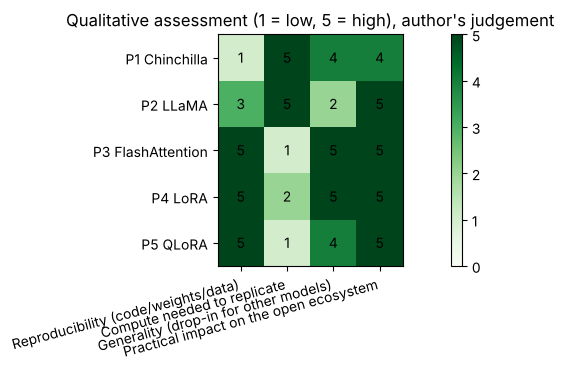

In [4]:
aspects = pd.DataFrame({
    "Reproducibility (code/weights/data)": {"P1 Chinchilla": 1, "P2 LLaMA": 3, "P3 FlashAttention": 5, "P4 LoRA": 5, "P5 QLoRA": 5},
    "Compute needed to replicate": {"P1 Chinchilla": 5, "P2 LLaMA": 5, "P3 FlashAttention": 1, "P4 LoRA": 2, "P5 QLoRA": 1},
    "Generality (drop-in for other models)": {"P1 Chinchilla": 4, "P2 LLaMA": 2, "P3 FlashAttention": 5, "P4 LoRA": 5, "P5 QLoRA": 4},
    "Practical impact on the open ecosystem": {"P1 Chinchilla": 4, "P2 LLaMA": 5, "P3 FlashAttention": 5, "P4 LoRA": 5, "P5 QLoRA": 5},
})
display(aspects)
fig, ax = plt.subplots(figsize=(10, 3.8))
im = ax.imshow(aspects.values, cmap="Greens", vmin=0, vmax=5)
ax.set_xticks(range(aspects.shape[1])); ax.set_xticklabels(aspects.columns, rotation=15, ha="right")
ax.set_yticks(range(aspects.shape[0])); ax.set_yticklabels(aspects.index)
for i in range(aspects.shape[0]):
    for j in range(aspects.shape[1]):
        ax.text(j, i, aspects.values[i, j], ha="center", va="center")
ax.set_title("Qualitative assessment (1 = low, 5 = high), author's judgement")
plt.colorbar(im, ax=ax, fraction=0.025); plt.tight_layout(); plt.show()

**Strengths, limitations and reproducibility.**

| Paper | Main strengths | Main limitations | Reproducibility |
|---|---|---|---|
| P1 Chinchilla | Rigorous: 400+ runs, 3 converging methods; changed industry practice | Fits depend on one dataset (MassiveText) and one setup; ignores inference cost; extrapolates beyond the fitted range; data repetition not studied | Low: no code, data or weights; only labs with huge compute can replicate |
| P2 LLaMA | Strong results with public data only; inference-efficient sizes; released weights started the open-LLM wave | Training data not fully released (only the recipe); research-only license at release; bias and toxicity still present; no instruction tuning in the paper | Medium: weights and inference code yes, training code and data no; replication costs millions |
| P3 FlashAttention | Exact (no quality loss), large real speed-ups, linear memory; theory (IO complexity) + engineering | Written for specific NVIDIA GPUs (custom CUDA, A100 tuning); attention-only (MLP untouched); harder to port to new hardware | High: open-source code, cheap to verify |
| P4 LoRA | Huge savings, no inference latency, mergeable, simple; insight into the low intrinsic rank of updates | Rank and target layers are hyper-parameters; may underperform full fine-tuning on tasks that need large changes; does not reduce memory for the frozen base | High: code released, cheap experiments |
| P5 QLoRA | Democratises fine-tuning of 33–65 B models; careful ablations; honest analysis of GPT-4-as-judge biases | Slower than 16-bit LoRA (de-quantization overhead); chatbot benchmarks are small and judged by a model; 4-bit inference quality and efficiency are not the focus | High: bitsandbytes + PEFT, adapters released |

### 3.3 Reproducing some quantitative claims
**(a) Chinchilla vs. LLaMA: tokens per parameter.** Chinchilla's rule is about 20 tokens per parameter. The token counts below are those reported in the papers.

,model,params_B,tokens_B,tokens_per_param,train_FLOPs (6ND),"chinchilla-optimal tokens (20N, B)"
0,GPT-3,175.0,300,1.7,3.15e+23,3500.0
1,Gopher,280.0,300,1.1,5.04e+23,5600.0
2,Chinchilla,70.0,1400,20.0,5.88e+23,1400.0
3,LLaMA-7B,6.7,1000,149.3,4.02e+22,134.0
4,LLaMA-13B,13.0,1000,76.9,7.80e+22,260.0
5,LLaMA-33B,32.5,1400,43.1,2.73e+23,650.0
6,LLaMA-65B,65.2,1400,21.5,5.48e+23,1304.0


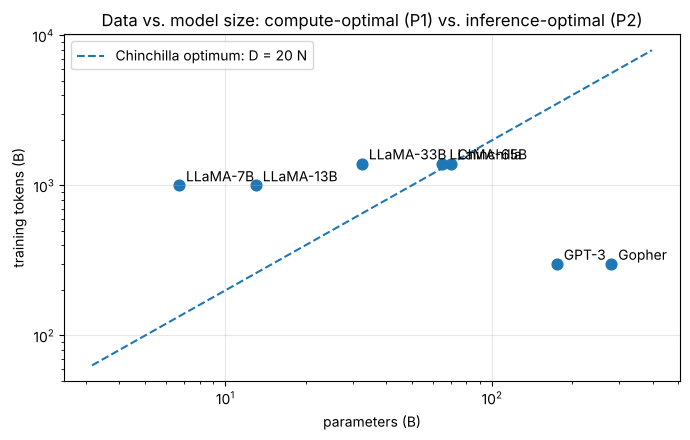

In [5]:
models = pd.DataFrame([
    ("GPT-3", 175, 300), ("Gopher", 280, 300), ("Chinchilla", 70, 1400),
    ("LLaMA-7B", 6.7, 1000), ("LLaMA-13B", 13, 1000), ("LLaMA-33B", 32.5, 1400), ("LLaMA-65B", 65.2, 1400),
], columns=["model", "params_B", "tokens_B"])
models["tokens_per_param"] = (models.tokens_B / models.params_B).round(1)
models["train_FLOPs (6ND)"] = (6 * models.params_B * 1e9 * models.tokens_B * 1e9).map(lambda x: f"{x:.2e}")
models["chinchilla-optimal tokens (20N, B)"] = (20 * models.params_B).round(0)
display(models)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(models.params_B, models.tokens_B, s=60)
for _, r in models.iterrows():
    ax.annotate(r.model, (r.params_B, r.tokens_B), xytext=(5, 3), textcoords="offset points")
x = np.logspace(0.5, 2.6, 50); ax.plot(x, 20 * x, "--", label="Chinchilla optimum: D = 20 N")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("parameters (B)"); ax.set_ylabel("training tokens (B)")
ax.set_title("Data vs. model size: compute-optimal (P1) vs. inference-optimal (P2)"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

GPT-3 and Gopher sit **far below** the compute-optimal line (1–2 tokens per parameter); Chinchilla sits on it (20). LLaMA-7B and LLaMA-13B sit **well above** it (77–150 tokens per parameter): they spend extra training compute to get small models that are cheap to serve. This is P2's explicit argument against using P1's rule for deployment.

**(b) LoRA: trainable parameters.** We count the parameters for a LLaMA-7B-shaped model (d = 4096, 32 layers) analytically, and check the formula with 🤗 PEFT on a small real model.

In [6]:
d, layers = 4096, 32
full_attn = layers * 4 * d * d                       # Wq, Wk, Wv, Wo
total_params = 6.7e9
rows = []
for r in [1, 4, 8, 16, 64]:
    lora_qv = layers * 2 * (2 * d * r)                # A (r x d) + B (d x r) for Wq and Wv
    rows.append({"rank r": r, "LoRA params (Wq,Wv)": f"{lora_qv/1e6:.2f} M",
                 "% of 6.7B model": f"{100*lora_qv/total_params:.4f} %", "reduction vs full FT": f"{total_params/lora_qv:,.0f} x"})
display(pd.DataFrame(rows))
print("GPT-3 175B, r=4 on Wq,Wv (d=12288, 96 layers):",
      f"{96*2*2*12288*4/1e6:.1f} M trainable params -> {175e9/(96*2*2*12288*4):,.0f}x fewer than full fine-tuning")

,rank r,"LoRA params (Wq,Wv)",% of 6.7B model,reduction vs full FT
0,1,0.52 M,0.0078 %,"12,779 x"
1,4,2.10 M,0.0313 %,"3,195 x"
2,8,4.19 M,0.0626 %,"1,597 x"
3,16,8.39 M,0.1252 %,799 x
4,64,33.55 M,0.5008 %,200 x


GPT-3 175B, r=4 on Wq,Wv (d=12288, 96 layers): 18.9 M trainable params -> 9,272x fewer than full fine-tuning


In [7]:
from transformers import AutoModelForCausalLM
from peft import LoraConfig, get_peft_model
base = AutoModelForCausalLM.from_pretrained("gpt2")
peft_model = get_peft_model(base, LoraConfig(r=4, lora_alpha=8, target_modules=["c_attn"], fan_in_fan_out=True, task_type="CAUSAL_LM"))
peft_model.print_trainable_parameters()
expected = 12 * (4 * 768 + 3 * 768 * 4)                # c_attn: 768 -> 2304 (q, k, v fused)
print("analytical count:", expected)

trainable params: 147,456 || all params: 124,587,264 || trainable%: 0.1184
analytical count: 147456


With r = 4 on W_q and W_v, GPT-3 needs only **≈ 18.9 M trainable parameters**, about **9 300× fewer than 175 B**. That is the same order of magnitude as the paper's "10 000×" reduction (r = 1–2 gives more than 10 000×). For a 7 B model the adapter is **0.03 %** of the weights at r = 4. PEFT's count on GPT-2 (147 456 trainable parameters, 0.12 %) matches our analytical formula exactly.

**(c) QLoRA: memory needed to fine-tune.** Weight memory only (activations and LoRA states add a few GB).

,full FT (16-bit weights + grads + Adam fp32 ≈ 16 B/param),LoRA (frozen 16-bit weights),QLoRA (NF4 + double quant ≈ 4.127 bits)
model,,,
LLaMA-7B,100,12.5,3.2
LLaMA-13B,194,24.2,6.2
LLaMA-33B,484,60.5,15.6
LLaMA-65B,972,121.4,31.3


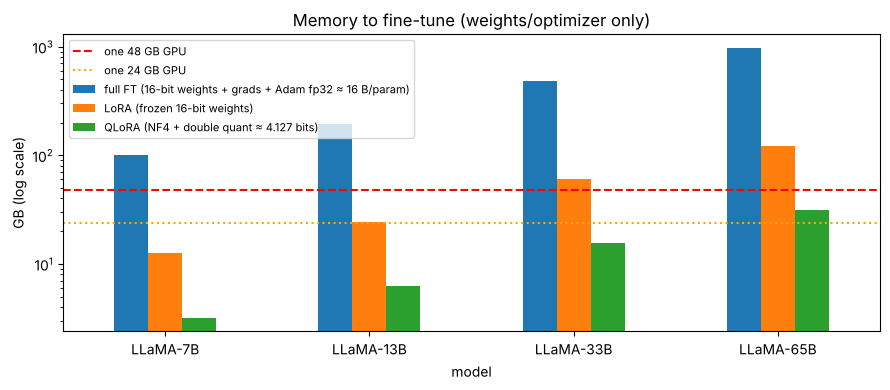

In [8]:
def gb(params_b, bits): return params_b * 1e9 * bits / 8 / 1024**3
rows = []
for name, p in [("LLaMA-7B", 6.7), ("LLaMA-13B", 13), ("LLaMA-33B", 32.5), ("LLaMA-65B", 65.2)]:
    rows.append({"model": name,
                 "full FT (16-bit weights + grads + Adam fp32 ≈ 16 B/param)": round(p * 1e9 * 16 / 1024**3),
                 "LoRA (frozen 16-bit weights)": round(gb(p, 16), 1),
                 "QLoRA (NF4 + double quant ≈ 4.127 bits)": round(gb(p, 4.127), 1)})
mem = pd.DataFrame(rows).set_index("model")
display(mem)
mem.plot.bar(figsize=(9, 4), logy=True, rot=0)
plt.axhline(48, color="red", ls="--", label="one 48 GB GPU"); plt.axhline(24, color="orange", ls=":", label="one 24 GB GPU")
plt.ylabel("GB (log scale)"); plt.title("Memory to fine-tune (weights/optimizer only)"); plt.legend(fontsize=8); plt.tight_layout(); plt.show()

Only QLoRA brings **65 B under the 48 GB line** (≈ 31 GB of weights plus adapters and activations), reproducing P5's headline claim. 4.127 bits per parameter is 4-bit NF4 plus the double-quantized constants, as reported in P5. Full fine-tuning of the same model needs ≈ 1 TB.

**(d) FlashAttention: why IO matters.** The size of the attention matrix that standard attention writes to HBM, per head and per sequence (fp16):

In [9]:
for n in [512, 1024, 2048, 4096, 16384, 65536]:
    print(f"seq {n:>6}: N x N attention matrix = {n*n*2/1024**2:>9,.1f} MB per head   (FlashAttention: O(N) memory, never materialised)")

seq    512: N x N attention matrix =       0.5 MB per head   (FlashAttention: O(N) memory, never materialised)
seq   1024: N x N attention matrix =       2.0 MB per head   (FlashAttention: O(N) memory, never materialised)
seq   2048: N x N attention matrix =       8.0 MB per head   (FlashAttention: O(N) memory, never materialised)
seq   4096: N x N attention matrix =      32.0 MB per head   (FlashAttention: O(N) memory, never materialised)
seq  16384: N x N attention matrix =     512.0 MB per head   (FlashAttention: O(N) memory, never materialised)
seq  65536: N x N attention matrix =   8,192.0 MB per head   (FlashAttention: O(N) memory, never materialised)


## 4. Insights and reflection

**Trends and patterns.**
1. **From "bigger" to "smarter" scaling.** The narrative moves from parameter count (GPT-3, Gopher) to **data-optimal** (P1) and then **inference-optimal** (P2) training. Today's small models (Mistral 7B, Llama 3 8B trained on 15 T tokens) push P2's logic further still.
2. **Efficiency through the *systems* lens.** P3 shows that the right cost model is *memory traffic, not FLOPs*. P5 likewise wins mostly through *memory* (4-bit storage, paged optimizers). Efficiency research has become hardware-aware co-design.
3. **Freeze and adapt.** P4 and P5 establish that a strong frozen foundation plus a tiny adapter captures most of the benefit of full fine-tuning, because the necessary updates have **low intrinsic rank**.
4. **Democratisation.** Each paper lowers the entry barrier: open weights (P2), open kernels (P3), cheap fine-tuning (P4), consumer-GPU fine-tuning (P5). Together they enabled the open-model ecosystem (Alpaca, Vicuna, Guanaco, Mistral, Llama 2/3 fine-tunes).
5. **Data quality over quantity** appears twice: in P2 (curated public data) and P5 (9 k high-quality OASST1 samples beat 450 k FLAN samples for chat).

**Most promising or innovative approaches.**
- **QLoRA** is the most *practically* transformative: it combines quantization and PEFT and turned fine-tuning a 65 B model into a single-GPU task.
- **FlashAttention** is the most *technically* innovative: it is exact, rests on IO-complexity theory, and is now the default attention implementation (FlashAttention-2 and -3, PyTorch SDPA).
- **The Chinchilla scaling law** is the most *strategically* influential. It changed how every lab allocates its training budget.

**Common limitations and challenges.**
- **Reproducibility asymmetry:** the pre-training papers (P1, P2) cannot be replicated outside a few labs, and their data is not released. The efficiency methods (P3–P5) are cheap to verify.
- **Evaluation gaps:** benchmarks differ between papers. Automatic metrics (BLEU, ROUGE) and GPT-4-as-judge (P5) have known biases, and few papers measure factuality, robustness or energy consistently.
- **Hardware specificity:** custom CUDA kernels (P3) and 4-bit paging (P5) are tied to NVIDIA GPUs.
- **Trade-offs left implicit:** extra training compute in P2; slower QLoRA training through de-quantization; LoRA possibly underfitting tasks that need large parameter changes; scaling-law extrapolation outside the fitted range in P1.
- **Safety and bias** are acknowledged (P2's toxicity and bias analysis, P5's discussion of evaluation) but not solved by efficiency gains. Cheaper models are also easier to misuse.

**Future directions.**
- **Scaling laws that include inference and data repetition**: data-constrained scaling (Muennighoff *et al.*, 2023) and "beyond Chinchilla-optimal" laws that add the deployment cost.
- **Long-context efficiency**: FlashAttention-2 and -3, ring attention, state-space models and hybrids (Mamba) that challenge quadratic attention.
- **Better PEFT**: DoRA, adaptive rank (AdaLoRA), LoRA for mixture-of-experts, multi-adapter serving (S-LoRA).
- **Low-bit inference and training**: 2–4-bit post-training quantization (GPTQ, AWQ), FP8 training, quantization-aware fine-tuning.
- **Standardised, cost-aware evaluation**: reporting accuracy *together with* FLOPs, memory, latency and energy, plus robust human and LLM-judge protocols.

## 5. Conclusion
The five papers trace the **efficiency stack** of modern LLMs.
- **Chinchilla** showed that models were *under-trained* and that data and parameters should grow together.
- **LLaMA** turned this into openly released, inference-friendly models that beat models 10× larger.
- **FlashAttention** made attention fast and memory-linear by respecting the GPU memory hierarchy.
- **LoRA** reduced fine-tuning to learning a tiny low-rank update.
- **QLoRA** combined LoRA with 4-bit quantization, so that a 65 B model can be adapted on one GPU.

The small reproductions above (tokens per parameter, LoRA parameter counts, QLoRA memory budgets) are consistent with the papers' headline claims.

The common lesson is that **progress in LLMs increasingly comes from using compute and memory more intelligently, not just from adding more of it.** The field is evolving from a race for scale controlled by a few labs towards an ecosystem in which open foundation models, efficient kernels and parameter-efficient adaptation let small teams build specialised models. The open challenges are now less about *whether* we can train or adapt a model cheaply, and more about **evaluating** such models reliably, making efficiency methods **hardware-portable**, and ensuring that cheaper, more accessible models remain **safe and trustworthy**.

### References
1. Hoffmann, J., Borgeaud, S., Mensch, A., Buchatskaya, E., Cai, T., Rutherford, E., *et al.* (2022). Training Compute-Optimal Large Language Models. *NeurIPS 2022*. arXiv:2203.15556.
2. Touvron, H., Lavril, T., Izacard, G., Martinet, X., Lachaux, M.-A., Lacroix, T., *et al.* (2023). LLaMA: Open and Efficient Foundation Language Models. arXiv:2302.13971.
3. Dao, T., Fu, D. Y., Ermon, S., Rudra, A., & Ré, C. (2022). FlashAttention: Fast and Memory-Efficient Exact Attention with IO-Awareness. *NeurIPS 2022*. arXiv:2205.14135.
4. Hu, E. J., Shen, Y., Wallis, P., Allen-Zhu, Z., Li, Y., Wang, S., Wang, L., & Chen, W. (2022). LoRA: Low-Rank Adaptation of Large Language Models. *ICLR 2022*. arXiv:2106.09685.
5. Dettmers, T., Pagnoni, A., Holtzman, A., & Zettlemoyer, L. (2023). QLoRA: Efficient Finetuning of Quantized LLMs. *NeurIPS 2023*. arXiv:2305.14314.
6. (Background) Kaplan, J., *et al.* (2020). Scaling Laws for Neural Language Models. arXiv:2001.08361.